In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [7]:
url = "https://raw.githubusercontent.com/juanfratoledo10-cyber/proyecto-programaci-n-U/main/datos_paes_fisica.csv"
datos = np.loadtxt(url, delimiter=",", skiprows=1)

r_correctas = datos[:, 0]  # Respuestas correctas (P)
punt_paes = datos[:, 1]  # Puntaje PAES

In [5]:
#funciones propuestas
def f_lineal(x, m, b): #una función lineal
    return m * x + b


def f_poli3(x, a, b, c, d): #una función polinomica de grado 3
    return a * x**3 + b * x**2 + c * x + d


def f_potencia(x, a, b, c): #una función exponencial
    return a * (x**b) + c

popt_lin, _ = curve_fit(f_lineal, r_correctas, punt_paes)
popt_p3, _ = curve_fit(f_poli3, r_correctas, punt_paes)
popt_pot, _ = curve_fit(f_potencia, r_correctas, punt_paes, p0=[10.0, 1.0, 100.0])

[  9.66980178 170.30348599]


In [21]:
def evaluar_ajuste(nombre, func, popt, r_correctas, punt_paes):
    punt_pred = func(r_correctas, *popt)
    residuos = punt_paes - punt_pred

    chi2 = np.sum(residuos**2)
    ss_tot = np.sum((punt_paes - np.mean(punt_paes)) ** 2)
    r2 = 1.0 - (chi2 / ss_tot)

    print(f"{nombre:12s} | Params: {np.round(popt, 4)} | Chi2: {np.round(chi2, 2)} | R2: {np.round(r2, 5)}")

evaluar_ajuste("Lineal", f_lineal, popt_lin, r_correctas, punt_paes)
evaluar_ajuste("Polinomio 3", f_poli3, popt_p3, r_correctas, punt_paes)
evaluar_ajuste("Potencia", f_potencia, popt_pot, r_correctas, punt_paes)

Lineal       | Params: [  9.6698 170.3035] | Chi2: 50893.72 | R2: 0.98534
Polinomio 3  | Params: [ 2.900000e-03 -3.369000e-01  1.994400e+01  1.057905e+02] | Chi2: 5141.79 | R2: 0.99852
Potencia     | Params: [ 17.1875   0.8727 135.9295] | Chi2: 44887.89 | R2: 0.98707


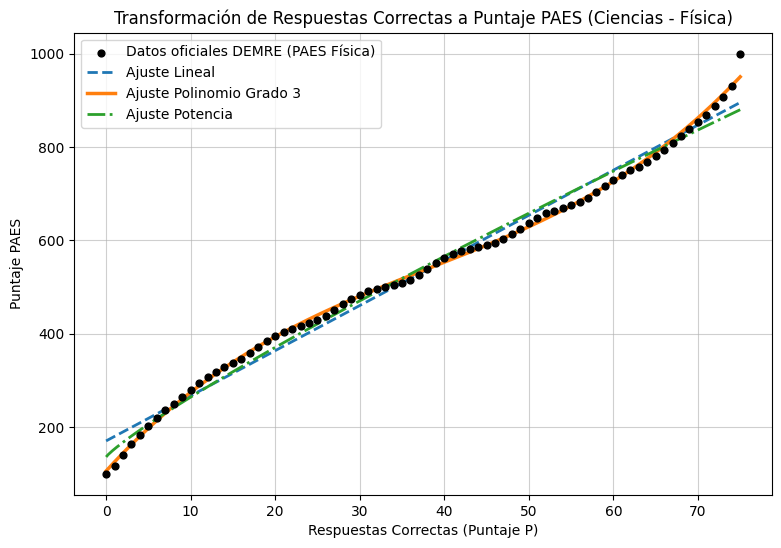

In [15]:
x_curva = np.linspace(0, 75, 300)


plt.figure(figsize=(9, 6))
plt.scatter(r_correctas,punt_paes,color="black",zorder=3,s=24,label="Datos oficiales DEMRE (PAES Física)",)

plt.plot(x_curva,f_lineal(x_curva, *popt_lin),"--",linewidth=2,label="Ajuste Lineal")

plt.plot(x_curva,f_poli3(x_curva, *popt_p3),"-",linewidth=2.5,label="Ajuste Polinomio Grado 3",)

plt.plot(x_curva,f_potencia(x_curva, *popt_pot),"-.",linewidth=2,label="Ajuste Potencia",)

plt.title("Transformación de Respuestas Correctas a Puntaje PAES (Ciencias - Física)")
plt.xlabel("Respuestas Correctas (Puntaje P)")
plt.ylabel("Puntaje PAES")
plt.legend()
plt.grid(True, alpha=0.6)
plt.savefig("grafico_ajuste_paes.png", dpi=300)
plt.show()